code from: https://colab.research.google.com/github/google-deepmind/mujoco_playground/blob/main/learning/notebooks/manipulation.ipynb#scrollTo=IbZxYDxzoz5R

In [1]:
# @title Check if MuJoCo installation was successful

import distutils.util
import os
import subprocess

if subprocess.run('nvidia-smi').returncode:
  raise RuntimeError(
      'Cannot communicate with GPU. '
      'Make sure you are using a GPU Colab runtime. '
      'Go to the Runtime menu and select Choose runtime type.'
  )

# Add an ICD config so that glvnd can pick up the Nvidia EGL driver.
# This is usually installed as part of an Nvidia driver package, but the Colab
# kernel doesn't install its driver via APT, and as a result the ICD is missing.
# (https://github.com/NVIDIA/libglvnd/blob/master/src/EGL/icd_enumeration.md)
NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
  with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
    f.write("""{
    "file_format_version" : "1.0.0",
    "ICD" : {
        "library_path" : "libEGL_nvidia.so.0"
    }
}
""")

# Configure MuJoCo to use the EGL rendering backend (requires GPU)
print('Setting environment variable to use GPU rendering:')
%env MUJOCO_GL=egl

try:
  print('Checking that the installation succeeded:')
  import mujoco

  mujoco.MjModel.from_xml_string('<mujoco/>')
except Exception as e:
  raise e from RuntimeError(
      'Something went wrong during installation. Check the shell output above '
      'for more information.\n'
      'If using a hosted Colab runtime, make sure you enable GPU acceleration '
      'by going to the Runtime menu and selecting "Choose runtime type".'
  )

print('Installation successful.')

# Tell XLA to use Triton GEMM, this improves steps/sec by ~30% on some GPUs
xla_flags = os.environ.get('XLA_FLAGS', '')
xla_flags += ' --xla_gpu_triton_gemm_any=True'
os.environ['XLA_FLAGS'] = xla_flags

Wed Oct 14 17:23:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.207                Driver Version: 570.207        CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090        On  |   00000000:01:00.0 Off |                  Off |
|  0%   47C    P8             33W /  480W |    1548MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

/tmp/ipykernel_2458677/1100621786.py:3: DeprecationWarning: The distutils package is deprecated and slated for removal in Python 3.12. Use setuptools or check PEP 632 for potential alternatives
  import distutils.util


In [2]:
# @title Import packages for plotting and creating graphics
import json
import itertools
import time
from typing import Callable, List, NamedTuple, Optional, Union
import numpy as np

# Graphics and plotting.
print("Installing mediapy:")
!command -v ffmpeg >/dev/null || (apt update && apt install -y ffmpeg)
!uv add -q mediapy
import mediapy as media
import matplotlib.pyplot as plt

# More legible printing from numpy.
np.set_printoptions(precision=3, suppress=True, linewidth=100)

Installing mediapy:


In [3]:
# @title Import MuJoCo, MJX, and Brax
from datetime import datetime
import functools
import os
from typing import Any, Dict, Sequence, Tuple, Union
from brax import base
from brax import envs
from brax import math
from brax.base import Base, Motion, Transform
from brax.base import State as PipelineState
from brax.envs.base import Env, PipelineEnv, State
from brax.io import html, mjcf, model
from brax.mjx.base import State as MjxState
from brax.training.agents.ppo import networks as ppo_networks
from brax.training.agents.ppo import train as ppo
from brax.training.agents.sac import networks as sac_networks
from brax.training.agents.sac import train as sac
from etils import epath
from flax import struct
from flax.training import orbax_utils
from IPython.display import HTML, clear_output
import jax
from jax import numpy as jp
from matplotlib import pyplot as plt
import mediapy as media
from ml_collections import config_dict
import mujoco
from mujoco import mjx
import numpy as np
from orbax import checkpoint as ocp

In [4]:
#@title Import The Playground

from mujoco_playground import wrapper
from mujoco_playground import registry

In [5]:
registry.manipulation.ALL_ENVS

('AlohaHandOver',
 'AlohaSinglePegInsertion',
 'PandaPickCube',
 'PandaPickCubeOrientation',
 'PandaPickCubeCartesian',
 'PandaOpenCabinet',
 'PandaRobotiqPushCube',
 'LeapCubeReorient',
 'LeapCubeRotateZAxis',
 'AeroCubeRotateZAxis')

In [6]:
env_name = 'PandaPickCube'
env = registry.load("PandaPickCube", config_overrides={"impl": "jax"})
env_cfg = registry.get_default_config(env_name)

E1014 17:23:17.600930 2459061 cuda_executor.cc:1743] Could not get kernel mode driver version: ( INVALID_ARGUMENT: Version does not match the format X.Y.Z )
E1014 17:23:17.613448 2458677 cuda_executor.cc:1743] Could not get kernel mode driver version: ( INVALID_ARGUMENT: Version does not match the format X.Y.Z )


In [7]:
env_cfg

action_repeat: 1
action_scale: 0.04
ctrl_dt: 0.02
episode_length: 150
impl: warp
naccdmax: 49152
naconmax: 49152
njmax: 128
reward_config:
  scales:
    box_target: 8.0
    gripper_box: 4.0
    no_floor_collision: 0.25
    robot_target_qpos: 0.3
sim_dt: 0.005

In [8]:
from mujoco_playground.config import manipulation_params
ppo_params = manipulation_params.brax_ppo_config(env_name)
ppo_params

action_repeat: 1
batch_size: 512
discounting: 0.97
entropy_cost: 0.02
episode_length: 150
learning_rate: 0.001
network_factory:
  policy_hidden_layer_sizes: !!python/tuple
  - 32
  - 32
  - 32
  - 32
  policy_obs_key: state
  value_hidden_layer_sizes: !!python/tuple
  - 256
  - 256
  - 256
  - 256
  - 256
  value_obs_key: state
normalize_observations: true
num_envs: 2048
num_evals: 4
num_minibatches: 32
num_resets_per_eval: 10
num_timesteps: 20000000
num_updates_per_batch: 8
reward_scaling: 1.0
unroll_length: 10

In [9]:
x_data, y_data, y_dataerr = [], [], []
times = [datetime.now()]


def progress(num_steps, metrics):
  clear_output(wait=True)

  times.append(datetime.now())
  x_data.append(num_steps)
  y_data.append(metrics["eval/episode_reward"])
  y_dataerr.append(metrics["eval/episode_reward_std"])

  plt.xlim([0, ppo_params["num_timesteps"] * 1.25])
  plt.xlabel("# environment steps")
  plt.ylabel("reward per episode")
  plt.title(f"y={y_data[-1]:.3f}")
  plt.errorbar(x_data, y_data, yerr=y_dataerr, color="blue")

  display(plt.gcf())

ppo_training_params = dict(ppo_params)
network_factory = ppo_networks.make_ppo_networks
if "network_factory" in ppo_params:
  del ppo_training_params["network_factory"]
  network_factory = functools.partial(
      ppo_networks.make_ppo_networks,
      **ppo_params.network_factory
  )

train_fn = functools.partial(
    ppo.train, **dict(ppo_training_params),
    network_factory=network_factory,
    progress_fn=progress,
    seed=1
)

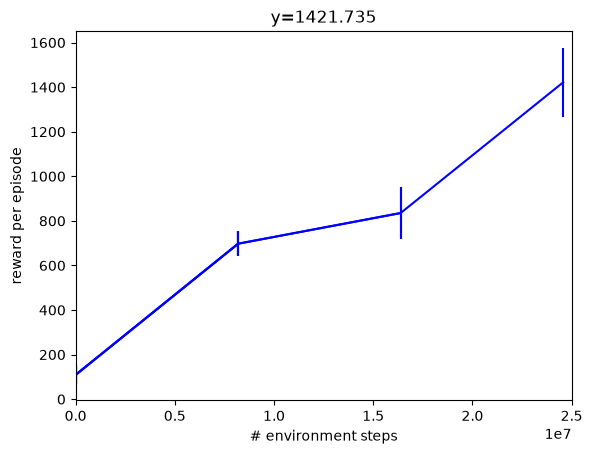

time to jit: 0:00:23.826867
time to train: 0:03:28.475330


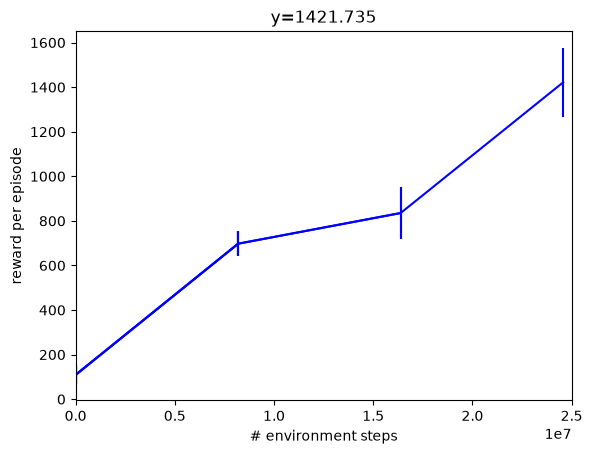

In [10]:
make_inference_fn, params, metrics = train_fn(
    environment=env,
    wrap_env_fn=wrapper.wrap_for_brax_training,
)
print(f"time to jit: {times[1] - times[0]}")
print(f"time to train: {times[-1] - times[1]}")

In [11]:
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)
jit_inference_fn = jax.jit(make_inference_fn(params, deterministic=True))

In [ ]:
rng = jax.random.PRNGKey(42)
rollout = []
n_episodes = 1

for _ in range(n_episodes):
  state = jit_reset(rng)
  rollout.append(state)
  for i in range(env_cfg.episode_length):
    act_rng, rng = jax.random.split(rng)
    ctrl, _ = jit_inference_fn(state.obs, act_rng)
    state = jit_step(state, ctrl)
    rollout.append(state)

render_every = 1
frames = env.render(rollout[::render_every])
rewards = [s.reward for s in rollout]
media.show_video(frames, fps=1.0 / env.dt / render_every)

100%|██████████| 151/151 [00:00<00:00, 859.94it/s]


This browser does not support the video tag.


In [13]:
import pickle
with open("ppo_teacher_pandapickcube.pkl", "wb") as f:
    pickle.dump(jax.device_get(params), f)

In [15]:
state = jit_reset(jax.random.PRNGKey(42))
print(state.metrics.keys())
print(state.info.keys())

dict_keys(['box_target', 'gripper_box', 'no_floor_collision', 'out_of_bounds', 'robot_target_qpos'])
dict_keys(['reached_box', 'rng', 'target_pos'])


In [17]:
def box_pos(state):
    return state.data.xpos[env._obj_body]

def evaluate_teacher(n_episodes=50, seed=1000, thresh=0.05):
    rng = jax.random.PRNGKey(seed)
    results = []
    for ep in range(n_episodes):
        rng, reset_rng = jax.random.split(rng)
        state = jit_reset(reset_rng)
        min_dist = np.inf
        for t in range(env_cfg.episode_length):
            rng, act_rng = jax.random.split(rng)
            action, _ = jit_inference_fn(state.obs, act_rng)
            state = jit_step(state, action)
            dist = float(jp.linalg.norm(box_pos(state) - state.info["target_pos"]))
            min_dist = min(min_dist, dist)
            if state.done:
                break
        results.append(dict(
            final_dist=dist,
            min_dist=min_dist,
            success=dist < thresh,
            reached_box=bool(state.info["reached_box"]),
            length=t + 1,
        ))
    return results

res = evaluate_teacher()
print("success rate:", np.mean([r["success"] for r in res]))
print("reached box:", np.mean([r["reached_box"] for r in res]))
print("final dist (median):", np.median([r["final_dist"] for r in res]))

success rate: 1.0
reached box: 1.0
final dist (median): 0.0044949527364224195


In [18]:
print("max final dist:", np.max([r["final_dist"] for r in res]))

max final dist: 0.02768656425178051


In [19]:
print(set(r["length"] for r in res))

{150}
